In [ ]:
# =========================================================
# VERIFICATION DU GPU
# =========================================================

import tensorflow as tf

# Afficher la version de TensorFlow
print("Version TensorFlow :", tf.__version__)

# Vérifier si un GPU est disponible
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

Version TensorFlow : 2.20.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image
import shutil
import random
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow :", tf.__version__)
print("NumPy :", np.__version__)

TensorFlow : 2.20.0
NumPy : 2.0.2


In [ ]:
# =========================================================
# CONNEXION DE GOOGLE DRIVE A GOOGLE COLAB
# =========================================================

from google.colab import drive


# =========================================================
# MONTAGE DU DRIVE
# =========================================================

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# =========================================================
# AFFICHER LE CONTENU DE GOOGLE DRIVE
# =========================================================

# Afficher les fichiers présents dans MyDrive
print(os.listdir('/content/drive/MyDrive'))

['Devoir .pdf', 'Colab Notebooks', 'archive (2).zip']


In [ ]:
# =========================================================
# DECOMPRESSION DU DATASET
# =========================================================

zip_path = "/content/drive/MyDrive/archive (2).zip"


# =========================================================
# DOSSIER DE DESTINATION
# =========================================================

# Le dataset sera extrait dans : /content/chest_xray

extract_path = "/content/chest_xray/"


# =========================================================
# EXTRACTION DU ZIP
# =========================================================

shutil.unpack_archive(zip_path, extract_path)


# =========================================================
# MESSAGE DE CONFIRMATION
# =========================================================

print("Dataset extrait avec succès !")

Dataset extrait avec succès !


In [ ]:
# =========================================================
# EXPLORATION DE LA STRUCTURE DU DATASET
# =========================================================



# =========================================================
# CHEMIN PRINCIPAL DU DATASET
# =========================================================

# Après extraction : le dataset se trouve ici

dataset_path = "/content/chest_xray/chest_xray"


# =========================================================
# AFFICHER LE CONTENU DU DOSSIER PRINCIPAL
# =========================================================

print("Contenu du dossier principal :")
print(os.listdir(dataset_path))


# =========================================================
# AFFICHER LE CONTENU DE TRAIN
# =========================================================

# train_path : chemin vers le dossier train

train_path = os.path.join(dataset_path, "train")

print("\nContenu du dossier train :")
print(os.listdir(train_path))


# =========================================================
# AFFICHER LE CONTENU DE TEST
# =========================================================

test_path = os.path.join(dataset_path, "test")

print("\nContenu du dossier test :")
print(os.listdir(test_path))


# =========================================================
# AFFICHER LE CONTENU DE VAL
# =========================================================

val_path = os.path.join(dataset_path, "val")

print("\nContenu du dossier val :")
print(os.listdir(val_path))

Contenu du dossier principal :
['val', 'train', 'chest_xray', '__MACOSX', 'test']

Contenu du dossier train :
['PNEUMONIA', 'NORMAL']

Contenu du dossier test :
['PNEUMONIA', 'NORMAL']

Contenu du dossier val :
['PNEUMONIA', 'NORMAL']


In [ ]:
# =========================================================
# COMPTAGE DES IMAGES PAR CLASSE
# =========================================================


# =========================================================
# CHEMINS PRINCIPAUX
# =========================================================

# Dossiers train / test / val
train_path = os.path.join(dataset_path, "train")
test_path = os.path.join(dataset_path, "test")
val_path = os.path.join(dataset_path, "val")


def count_images(folder_path):

    return len(os.listdir(folder_path))


# =========================================================
# TRAIN
# =========================================================

# Chemins des classes
train_normal = os.path.join(train_path, "NORMAL")
train_pneumonia = os.path.join(train_path, "PNEUMONIA")

# Comptage
num_train_normal = count_images(train_normal)
num_train_pneumonia = count_images(train_pneumonia)


# =========================================================
# TEST
# =========================================================

test_normal = os.path.join(test_path, "NORMAL")
test_pneumonia = os.path.join(test_path, "PNEUMONIA")

num_test_normal = count_images(test_normal)
num_test_pneumonia = count_images(test_pneumonia)


# =========================================================
# VALIDATION
# =========================================================

val_normal = os.path.join(val_path, "NORMAL")
val_pneumonia = os.path.join(val_path, "PNEUMONIA")

num_val_normal = count_images(val_normal)
num_val_pneumonia = count_images(val_pneumonia)


# =========================================================
# AFFICHAGE DES RESULTATS
# =========================================================

print("========== TRAIN ==========")
print("NORMAL :", num_train_normal)
print("PNEUMONIA :", num_train_pneumonia)

print("\n========== TEST ==========")
print("NORMAL :", num_test_normal)
print("PNEUMONIA :", num_test_pneumonia)

print("\n========== VALIDATION ==========")
print("NORMAL :", num_val_normal)
print("PNEUMONIA :", num_val_pneumonia)

========== TRAIN ==========
NORMAL : 1341
PNEUMONIA : 3875

========== TEST ==========
NORMAL : 234
PNEUMONIA : 390

========== VALIDATION ==========
NORMAL : 8
PNEUMONIA : 8


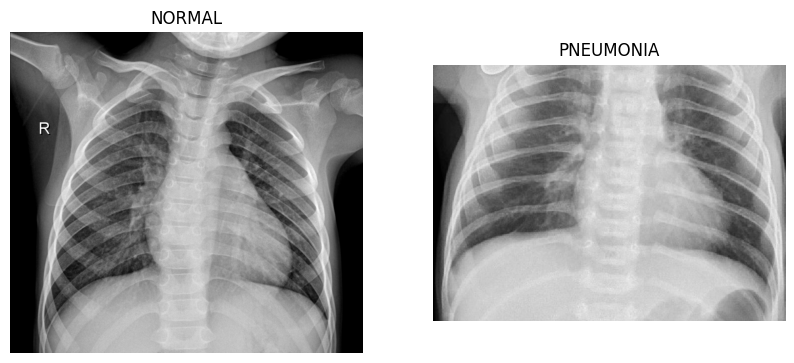

In [ ]:
# =========================================================
# AFFICHAGE D'EXEMPLES D'IMAGES
# =========================================================


# =========================================================
# CHEMINS DES DOSSIERS
# =========================================================

train_normal = os.path.join(
    dataset_path,
    "train",
    "NORMAL"
)

train_pneumonia = os.path.join(
    dataset_path,
    "train",
    "PNEUMONIA"
)


# =========================================================
# RECUPERATION DES NOMS DES IMAGES
# =========================================================

normal_images = os.listdir(train_normal)

pneumonia_images = os.listdir(train_pneumonia)


# =========================================================
# SELECTION D'UNE IMAGE
# =========================================================


normal_image_path = os.path.join(
    train_normal,
    normal_images[0]
)

pneumonia_image_path = os.path.join(
    train_pneumonia,
    pneumonia_images[0]
)


# =========================================================
# OUVERTURE DES IMAGES
# =========================================================

normal_image = Image.open(normal_image_path)

pneumonia_image = Image.open(
    pneumonia_image_path
)


plt.figure(figsize=(10,5))


# =========================================================
# IMAGE NORMAL
# =========================================================


plt.subplot(1,2,1)

plt.imshow(normal_image,cmap='gray')

plt.title("NORMAL")

plt.axis("off")


# =========================================================
# IMAGE PNEUMONIA
# =========================================================

plt.subplot(1,2,2)

plt.imshow(pneumonia_image,cmap='gray')

plt.title("PNEUMONIA")

plt.axis("off")

plt.show()

In [ ]:
# =========================================================
# ANALYSE DES DIMENSIONS DES IMAGES
# =========================================================


# =========================================================
# CHEMINS DES DOSSIERS
# =========================================================

train_normal = os.path.join(
    dataset_path,
    "train",
    "NORMAL"
)

train_pneumonia = os.path.join(
    dataset_path,
    "train",
    "PNEUMONIA"
)


# =========================================================
# RECUPERATION D'UNE IMAGE
# =========================================================


normal_image_name = os.listdir(train_normal)[0]

pneumonia_image_name = os.listdir(
    train_pneumonia
)[0]


# =========================================================
# CREATION DES CHEMINS COMPLETS
# =========================================================

normal_image_path = os.path.join(
    train_normal,
    normal_image_name
)

pneumonia_image_path = os.path.join(
    train_pneumonia,
    pneumonia_image_name
)


# =========================================================
# OUVERTURE DES IMAGES
# =========================================================

normal_image = Image.open(normal_image_path)

pneumonia_image = Image.open(
    pneumonia_image_path
)


# =========================================================
# AFFICHAGE DES INFORMATIONS
# =========================================================

print("========== IMAGE NORMAL ==========")

print("Dimensions :", normal_image.size)

print("Mode couleur :", normal_image.mode)


print("\n========== IMAGE PNEUMONIA ==========")

print("Dimensions :", pneumonia_image.size)

print("Mode couleur :", pneumonia_image.mode)

========== IMAGE NORMAL ==========
Dimensions : (1952, 1777)
Mode couleur : L

========== IMAGE PNEUMONIA ==========
Dimensions : (703, 511)
Mode couleur : RGB


In [ ]:
# =========================================================
# ANALYSE GLOBALE DES DIMENSIONS DES IMAGES
# =========================================================


# =========================================================
# DOSSIERS DES CLASSES
# =========================================================

normal_folder = os.path.join(
    dataset_path,
    "train",
    "NORMAL"
)

pneumonia_folder = os.path.join(
    dataset_path,
    "train",
    "PNEUMONIA"
)


# =========================================================
# LISTES POUR STOCKER LES DIMENSIONS
# =========================================================


widths = []

heights = []


# =========================================================
# FONCTION D'ANALYSE
# =========================================================

def analyze_dimensions(folder_path):

    image_names = os.listdir(folder_path)

    for image_name in image_names:

        image_path = os.path.join(
            folder_path,
            image_name
        )

        image = Image.open(image_path)

        width, height = image.size

        widths.append(width)

        heights.append(height)


# =========================================================
# ANALYSE DES DEUX CLASSES
# =========================================================

analyze_dimensions(normal_folder)

analyze_dimensions(pneumonia_folder)


# =========================================================
# CALCUL DES STATISTIQUES
# =========================================================

min_width = np.min(widths)

min_height = np.min(heights)

max_width = np.max(widths)

max_height = np.max(heights)

mean_width = np.mean(widths)

mean_height = np.mean(heights)

print("========== ANALYSE GLOBALE DES DIMENSIONS ==========")

print("\nLargeur minimale :", min_width)

print("Largeur maximale :", max_width)

print("Largeur moyenne :", round(mean_width, 2))


print("\nHauteur minimale :", min_height)

print("Hauteur maximale :", max_height)

print("Hauteur moyenne :", round(mean_height, 2))

========== ANALYSE GLOBALE DES DIMENSIONS ==========

Largeur minimale : 384
Largeur maximale : 2916
Largeur moyenne : 1320.61

Hauteur minimale : 127
Hauteur maximale : 2663
Hauteur moyenne : 968.07


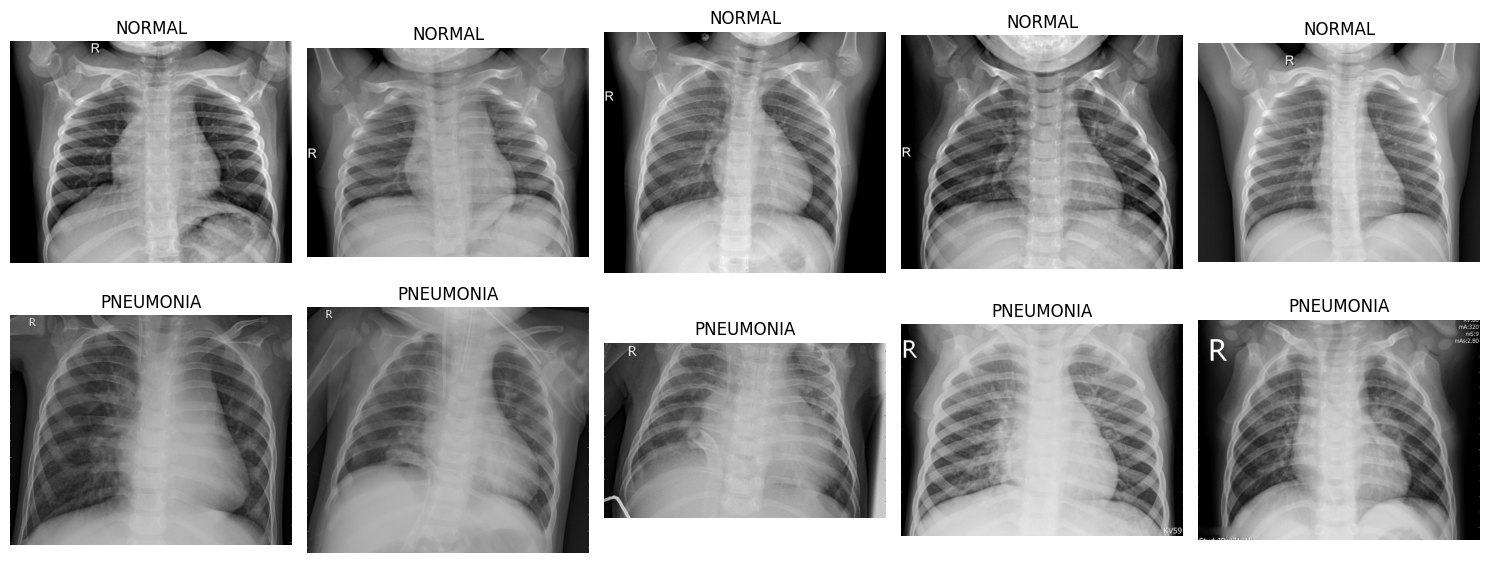

In [ ]:
# =========================================================
# AFFICHAGE D'UNE GALERIE D'IMAGES
# =========================================================

# =========================================================
# DOSSIERS DES CLASSES
# =========================================================

normal_folder = os.path.join(
    dataset_path,
    "train",
    "NORMAL"
)

pneumonia_folder = os.path.join(
    dataset_path,
    "train",
    "PNEUMONIA"
)


# =========================================================
# RECUPERATION DES NOMS DES IMAGES
# =========================================================

normal_images = os.listdir(normal_folder)

pneumonia_images = os.listdir(
    pneumonia_folder
)


# =========================================================
# SELECTION ALEATOIRE DES IMAGES
# =========================================================

selected_normal = random.sample(
    normal_images,
    5
)

selected_pneumonia = random.sample(
    pneumonia_images,
    5
)

plt.figure(figsize=(15,6))


# =========================================================
# AFFICHAGE DES IMAGES NORMAL
# =========================================================

for i, image_name in enumerate(selected_normal):

    image_path = os.path.join(
        normal_folder,
        image_name
    )

    image = Image.open(image_path)

    plt.subplot(2,5,i+1)

    plt.imshow(image, cmap='gray')

    plt.title("NORMAL")

    plt.axis("off")


# =========================================================
# AFFICHAGE DES IMAGES PNEUMONIA
# =========================================================

for i, image_name in enumerate(
    selected_pneumonia
):

    image_path = os.path.join(
        pneumonia_folder,
        image_name
    )

    image = Image.open(image_path)

    plt.subplot(2,5,i+6)

    plt.imshow(image, cmap='gray')

    plt.title("PNEUMONIA")

    plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
# =========================================================
# RECONSTRUCTION PROFESSIONNELLE DES DATASETS
# AVEC validation_split
# =========================================================


# =========================================================
# CHEMIN DU DOSSIER TRAIN
# =========================================================

train_dir = os.path.join(
    dataset_path,
    "train"
)

image_size = (224, 224)

batch_size = 32

validation_split = 0.2

seed = 42

# =========================================================
# CREATION DU DATASET TRAIN
# =========================================================

train_dataset = tf.keras.utils.image_dataset_from_directory(

    directory = train_dir,

    labels = "inferred",

    label_mode = "binary",

    image_size = image_size,

    batch_size = batch_size,

    shuffle = True,

    validation_split = validation_split,

    subset = "training",

    seed = seed
)


# =========================================================
# CREATION DU DATASET VALIDATION
# =========================================================

val_dataset = tf.keras.utils.image_dataset_from_directory(

    directory = train_dir,

    labels = "inferred",

    label_mode = "binary",

    image_size = image_size,

    batch_size = batch_size,

    shuffle = True,

    validation_split = validation_split,

    subset = "validation",

    seed = seed
)


# =========================================================
# DATASET TEST
# =========================================================

test_dataset = tf.keras.utils.image_dataset_from_directory(

    directory = os.path.join(
        dataset_path,
        "test"
    ),

    labels = "inferred",

    label_mode = "binary",

    image_size = image_size,

    batch_size = batch_size,

    shuffle = False
)

print("\n========== CLASSES DETECTEES ==========")

print(train_dataset.class_names)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.

========== CLASSES DETECTEES ==========
['NORMAL', 'PNEUMONIA']


In [ ]:
# =========================================================
# ANALYSE D'UN BATCH TENSORFLOW
# =========================================================

# =========================================================
# RECUPERATION D'UN BATCH
# =========================================================

for images, labels in train_dataset.take(1):

    print("========== IMAGES ==========")

    print("Shape des images :")

    print(images.shape)

    print("\n========== LABELS ==========")

    print("Shape des labels :")

    print(labels.shape)

    print("\n========== TYPES ==========")

    print("Type des images :")

    print(images.dtype)

    print("\nType des labels :")

    print(labels.dtype)


    # =====================================================
    # AFFICHAGE DE QUELQUES LABELS
    # =====================================================

    print("\n========== EXEMPLES DE LABELS ==========")

    print(labels[:10])

========== IMAGES ==========
Shape des images :
(32, 224, 224, 3)

========== LABELS ==========
Shape des labels :
(32, 1)

========== TYPES ==========
Type des images :
<dtype: 'float32'>

Type des labels :
<dtype: 'float32'>

========== EXEMPLES DE LABELS ==========
tf.Tensor(
[[1.]
 [1.]
 [1.]
 [1.]
 [0.]
 [1.]
 [0.]
 [1.]
 [1.]
 [1.]], shape=(10, 1), dtype=float32)


In [ ]:
# =========================================================
# NORMALISATION DES PIXELS
# =========================================================


# =========================================================
# CREATION DE LA COUCHE DE NORMALISATION
# =========================================================

normalization_layer = tf.keras.layers.Rescaling(
    1./255
)


# =========================================================
# APPLICATION DE LA NORMALISATION
# =========================================================

train_dataset = train_dataset.map(

    lambda x, y: (
        normalization_layer(x),
        y
    )
)


# =========================================================
# VALIDATION DATASET
# =========================================================

val_dataset = val_dataset.map(
    lambda x, y: (
        normalization_layer(x),
        y
    )
)


# =========================================================
# TEST DATASET
# =========================================================

test_dataset = test_dataset.map(
    lambda x, y: (
        normalization_layer(x),
        y
    )
)

print("Normalisation appliquée avec succès !")

Normalisation appliquée avec succès !


In [ ]:
# =========================================================
# ANALYSE COMPLETE DES PIXELS NORMALISES
# =========================================================

# =========================================================
# RECUPERATION D'UN BATCH
# =========================================================

for images, labels in train_dataset.take(1):


    # =====================================================
    # VALEUR MINIMALE
    # =====================================================

    min_value = tf.reduce_min(images)


    # =====================================================
    # VALEUR MAXIMALE
    # =====================================================

    max_value = tf.reduce_max(images)


    # =====================================================
    # MOYENNE DES PIXELS
    # =====================================================

    mean_value = tf.reduce_mean(images)


    # =====================================================
    # ECART-TYPE
    # =====================================================

    std_value = tf.math.reduce_std(images)


    # =====================================================
    # AFFICHAGE DES RESULTATS
    # =====================================================

    print("========== ANALYSE DES PIXELS ==========")

    print("\nValeur minimale :")
    print(min_value.numpy())


    print("\nValeur maximale :")
    print(max_value.numpy())


    print("\nMoyenne des pixels :")
    print(mean_value.numpy())


    print("\nEcart-type des pixels :")
    print(std_value.numpy())


    # =====================================================
    # AFFICHAGE DE QUELQUES PIXELS
    # =====================================================

    print("\n========== EXEMPLE DE PIXELS ==========")

    print(
        images[0][:5, :5, 0].numpy()
    )

========== ANALYSE DES PIXELS ==========

Valeur minimale :
0.0

Valeur maximale :
1.0

Moyenne des pixels :
0.4884454

Ecart-type des pixels :
0.24065875

========== EXEMPLE DE PIXELS ==========
[[0.2751401  0.31623152 0.32614297 0.34481797 0.34255958]
 [0.25813827 0.28598192 0.30791318 0.348617   0.3489421 ]
 [0.25497198 0.28942576 0.31186226 0.33116248 0.3609995 ]
 [0.24010855 0.26332286 0.32058826 0.33676472 0.3374475 ]
 [0.20938377 0.24796417 0.27245647 0.3374125  0.3544994 ]]


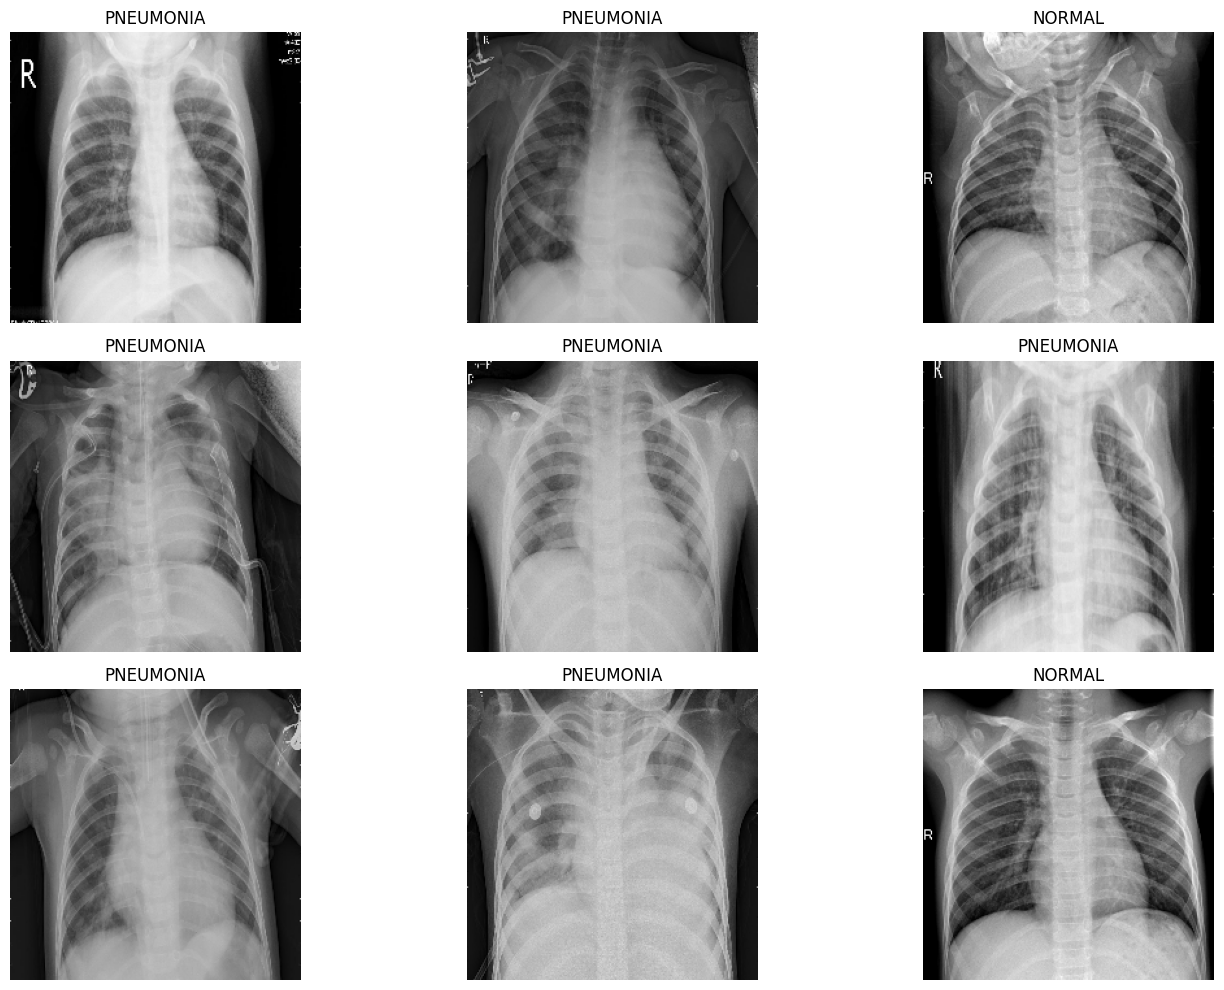

In [ ]:
# =========================================================
# AFFICHAGE DES IMAGES APRES PREPROCESSING
# =========================================================


# =========================================================
# RECUPERATION D'UN BATCH
# =========================================================

for images, labels in train_dataset.take(1):

    plt.figure(figsize=(15,10))

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i])

        label = labels[i].numpy()[0]


        # =================================================
        # CONVERSION LABEL -> TEXTE
        # =================================================

        if label == 0:

            class_name = "NORMAL"

        else:

            class_name = "PNEUMONIA"

        plt.title(class_name)

        plt.axis("off")

    plt.tight_layout()

    plt.show()

In [ ]:
# =========================================================
# DATA AUGMENTATION
# =========================================================

# =========================================================
# CREATION DU PIPELINE D'AUGMENTATION
# =========================================================

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.02
    ),

    tf.keras.layers.RandomZoom(
        0.1
    ),

    tf.keras.layers.RandomTranslation(
        height_factor = 0.1,
        width_factor = 0.1
    )

])


print("Pipeline de Data Augmentation créé avec succès !")

Pipeline de Data Augmentation créé avec succès !


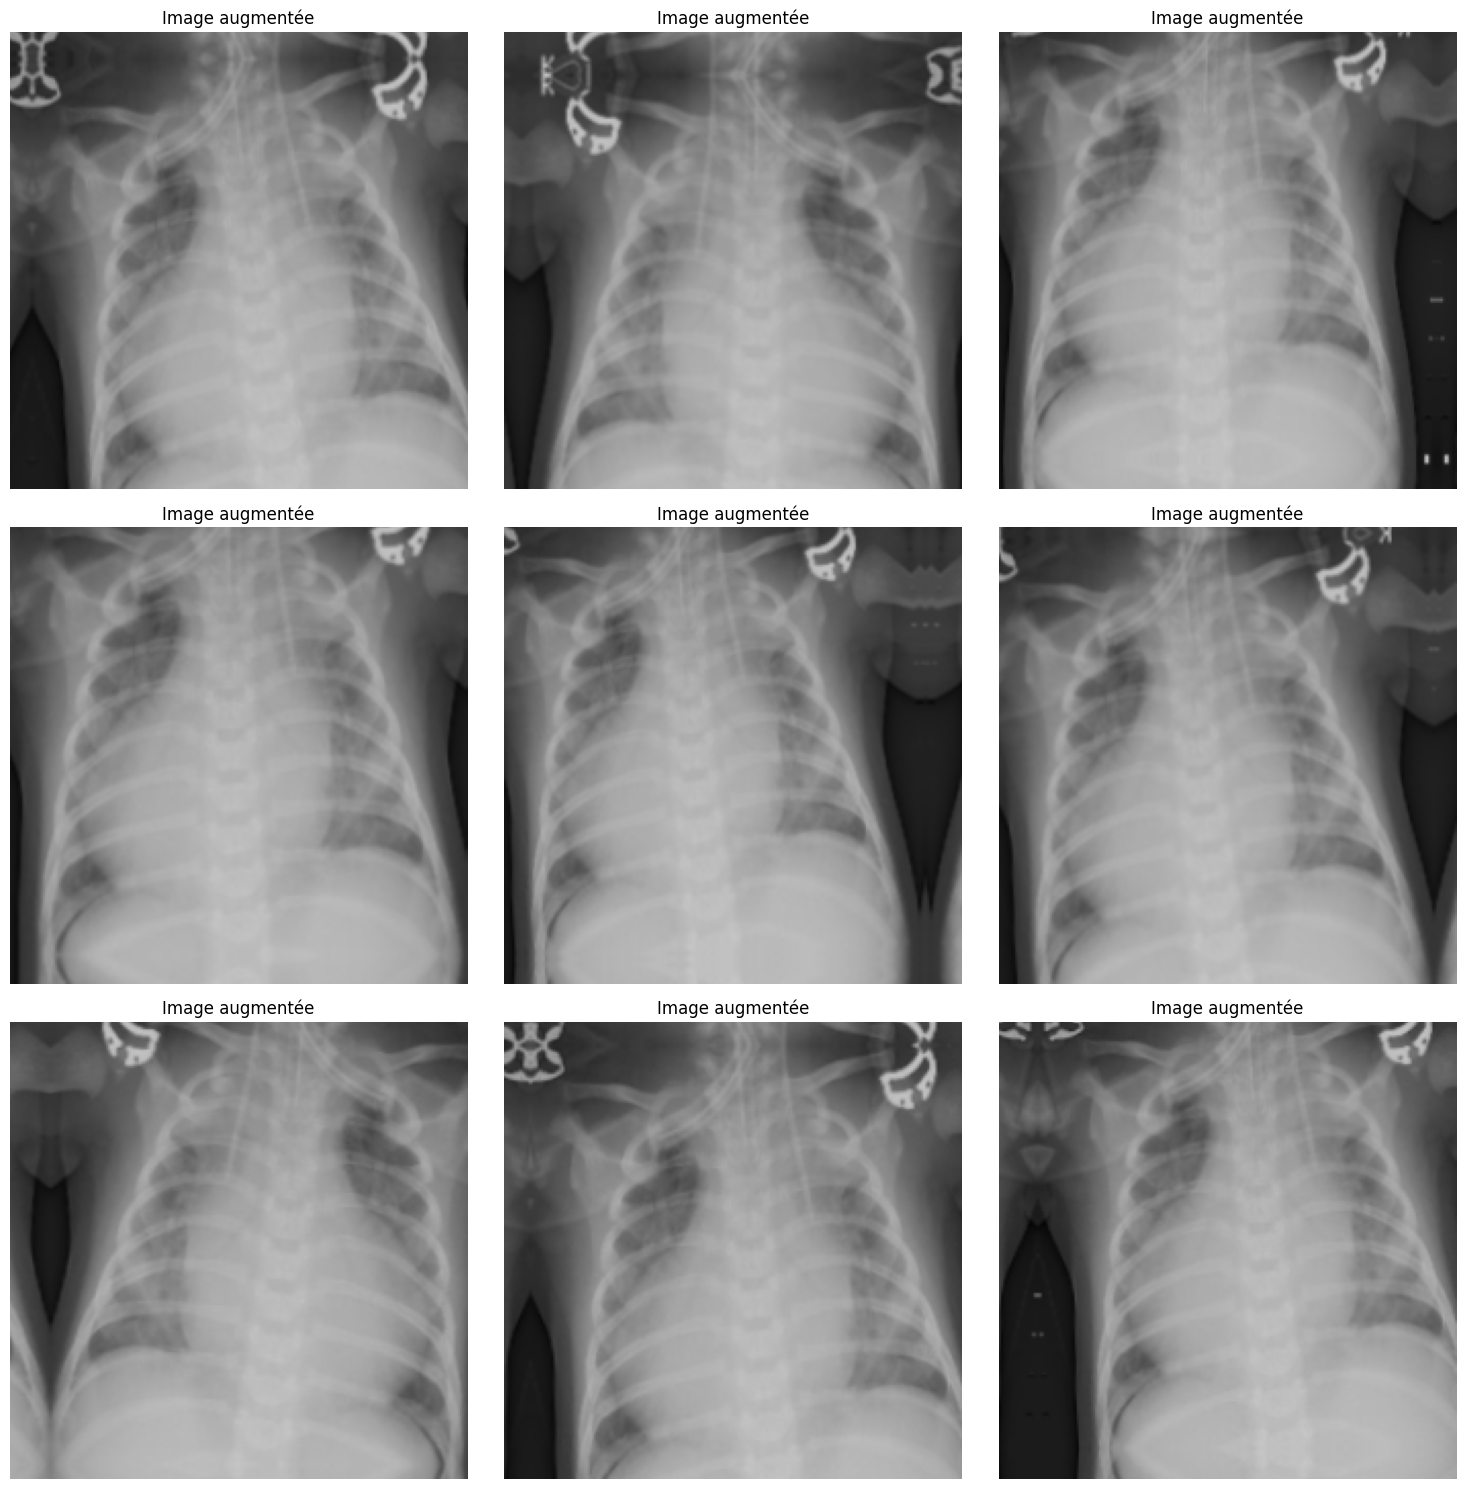

In [ ]:
# =========================================================
# VISUALISATION DE LA DATA AUGMENTATION
# =========================================================

# =========================================================
# RECUPERATION D'UN BATCH
# =========================================================

for images, labels in train_dataset.take(1):

    first_image = images[0]

    plt.figure(figsize=(15,15))

    for i in range(9):

        augmented_image = data_augmentation(
            tf.expand_dims(first_image, 0)
        )

        plt.subplot(3,3,i+1)

        plt.imshow(augmented_image[0])

        plt.title("Image augmentée")

        plt.axis("off")

    plt.tight_layout()

    plt.show()

In [ ]:
# =========================================================
# CALCUL DES CLASS WEIGHTS
# =========================================================

from sklearn.utils.class_weight import (
    compute_class_weight
)

all_labels = []

for images, labels in train_dataset:

    labels_numpy = labels.numpy()

    labels_numpy = labels_numpy.flatten()

    all_labels.extend(labels_numpy)

all_labels = np.array(all_labels)

classes = np.unique(all_labels)

class_weights = compute_class_weight(

    class_weight = "balanced",

    classes = classes,

    y = all_labels
)


# =========================================================
# CONVERSION EN DICTIONNAIRE
# =========================================================

class_weights = {

    i : class_weights[i]

    for i in range(len(class_weights))
}


print("========== CLASS WEIGHTS ==========")

print(class_weights)

========== CLASS WEIGHTS ==========
{0: np.float64(1.9107142857142858), 1: np.float64(0.6772151898734177)}


In [ ]:
# =========================================================
# CNN AMELIORE ET STABILISE
# =========================================================

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (

    Input,

    Conv2D,

    MaxPooling2D,

    Dropout,

    Dense,

    GlobalAveragePooling2D
)


# =========================================================
# CREATION DU MODELE
# =========================================================

model = Sequential([


    # =====================================================
    # INPUT LAYER
    # =====================================================

    Input(shape=(224, 224, 3)),


    # =====================================================
    # DATA AUGMENTATION
    # =====================================================

    data_augmentation,


    # =====================================================
    # BLOC CNN 1
    # =====================================================

    Conv2D(

        filters = 32,

        kernel_size = (3,3),

        activation = "relu",

        padding = "same"
    ),

    MaxPooling2D(pool_size=(2,2)),


    # =====================================================
    # BLOC CNN 2
    # =====================================================

    Conv2D(

        filters = 64,

        kernel_size = (3,3),

        activation = "relu",

        padding = "same"
    ),

    MaxPooling2D(pool_size=(2,2)),


    # =====================================================
    # BLOC CNN 3
    # =====================================================

    Conv2D(

        filters = 128,

        kernel_size = (3,3),

        activation = "relu",

        padding = "same"
    ),

    MaxPooling2D(pool_size=(2,2)),


    # =====================================================
    # BLOC CNN 4
    # =====================================================

    Conv2D(

        filters = 256,

        kernel_size = (3,3),

        activation = "relu",

        padding = "same"
    ),

    MaxPooling2D(pool_size=(2,2)),


    # =====================================================
    # DROPOUT
    # =====================================================

    Dropout(0.3),


    # =====================================================
    # GLOBAL AVERAGE POOLING
    # =====================================================

    GlobalAveragePooling2D(),


    # =====================================================
    # DENSE LAYER
    # =====================================================

    Dense(

        128,

        activation = "relu"
    ),


    # =====================================================
    # DROPOUT FINAL
    # =====================================================

    Dropout(0.3),


    # =====================================================
    # OUTPUT LAYER
    # =====================================================

    Dense(

        1,

        activation = "sigmoid"
    )

])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =========================================================
# COMPILATION DU MODELE CNN
# VERSION STABILISEE
# =========================================================

from tensorflow.keras.optimizers import Adam

optimizer = Adam(

    learning_rate = 0.0001
)

model.compile(

    optimizer = optimizer,

    loss = "binary_crossentropy",

    metrics = [

        "accuracy",

        tf.keras.metrics.Precision(),

        tf.keras.metrics.Recall(),

        tf.keras.metrics.AUC()
    ]
)

print("Modèle compilé avec succès !")

Modèle compilé avec succès !


In [ ]:
# =========================================================
# ENTRAINEMENT DU CNN
# =========================================================

# =========================================================
# IMPORTATION DES CALLBACKS
# =========================================================

from tensorflow.keras.callbacks import (

    EarlyStopping,

    ModelCheckpoint
)


# =========================================================
# EARLY STOPPING
# =========================================================

early_stopping = EarlyStopping(

    monitor = "val_loss",

    patience = 5,

    restore_best_weights = True
)


# =========================================================
# MODEL CHECKPOINT
# =========================================================

checkpoint = ModelCheckpoint(


    # =====================================================
    # NOM DU FICHIER
    # =====================================================

    filepath = "best_cnn_model.keras",


    # =====================================================
    # METRIQUE SURVEILLEE
    # =====================================================

    monitor = "val_loss",

    save_best_only = True,

    mode = "min",

    verbose = 1
)

epochs = 25

history = model.fit(

    train_dataset,

    validation_data = val_dataset,

    epochs = epochs,

    callbacks = [

        early_stopping,

        checkpoint
    ],

    verbose = 1
)

print("\nEntraînement terminé avec succès !")

Epoch 1/25
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.7264 - auc: 0.4791 - loss: 0.6088 - precision: 0.7363 - recall: 0.9746
Epoch 1: val_loss improved from None to 0.55950, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 42s 252ms/step - accuracy: 0.7374 - auc: 0.4668 - loss: 0.5913 - precision: 0.7392 - recall: 0.9955 - val_accuracy: 0.7613 - val_auc: 0.4242 - val_loss: 0.5595 - val_precision: 0.7613 - val_recall: 1.0000
Epoch 2/25
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.7310 - auc: 0.4725 - loss: 0.5903 - precision: 0.7310 - recall: 1.0000
Epoch 2: val_loss did not improve from 0.55950
131/131 ━━━━━━━━━━━━━━━━━━━━ 33s 253ms/step - accuracy: 0.7381 - auc: 0.5065 - loss: 0.5802 - precision: 0.7383 - recall: 0.9997 - val_accuracy: 0.7565 - val_auc: 0.6815 - val_loss: 0.5597 - val_precision: 0.7606 - val_recall: 0.9924
Epoch 3/25
130/131 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy:

In [ ]:
# =========================================================
# CHARGEMENT DU MEILLEUR MODELE
# =========================================================

from tensorflow.keras.models import load_model

model = load_model(

    "best_cnn_model.keras"
)

print("Meilleur modèle chargé avec succès !")

Meilleur modèle chargé avec succès !


In [ ]:
# =========================================================
# EVALUATION FINALE DU MEILLEUR MODELE
# =========================================================

# =========================================================
# EVALUATION SUR LE TEST SET
# =========================================================

test_results = model.evaluate(

    test_dataset,

    verbose = 1
)


# =========================================================
# RECUPERATION DES NOMS DES METRIQUES
# =========================================================

metric_names = model.metrics_names

print("\n========== RESULTATS FINAUX TEST SET ==========\n")

for name, value in zip(

    metric_names,

    test_results
):

    print(f"{name} : {value:.4f}")

print("\nEvaluation finale terminée avec succès !")

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 264ms/step - accuracy: 0.8029 - auc: 0.8938 - loss: 0.4227 - precision: 0.7987 - recall: 0.9154

========== RESULTATS FINAUX TEST SET ==========

loss : 0.4227
compile_metrics : 0.8029

Evaluation finale terminée avec succès !


In [ ]:
# =========================================================
# PREDICTIONS CENTRALISEES
# =========================================================

true_labels = np.concatenate([

    y for x, y in test_dataset

])

predictions = model.predict(

    test_dataset
)

print("Prédictions calculées avec succès !")

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 129ms/step
Prédictions calculées avec succès !


20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step


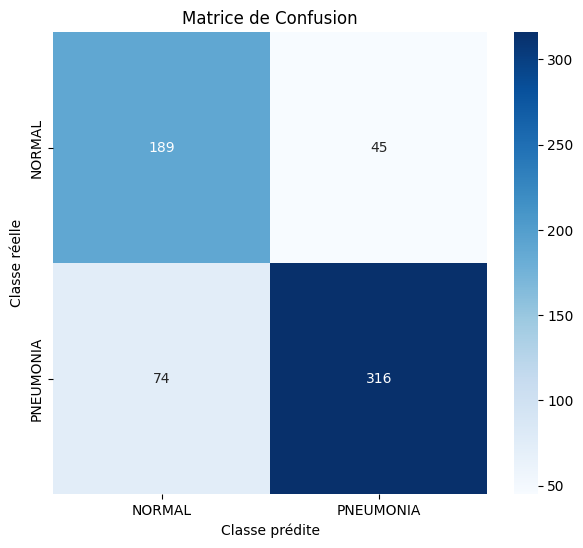


========== CLASSIFICATION REPORT ==========

              precision    recall  f1-score   support

      NORMAL       0.72      0.81      0.76       234
   PNEUMONIA       0.88      0.81      0.84       390

    accuracy                           0.81       624
   macro avg       0.80      0.81      0.80       624
weighted avg       0.82      0.81      0.81       624


========== F1-SCORE ==========

F1-score : 0.8415


In [ ]:
# =========================================================
# MATRICE DE CONFUSION + CLASSIFICATION REPORT
# =========================================================

from sklearn.metrics import (

    confusion_matrix,

    classification_report,

    f1_score
)


# =========================================================
# RECUPERATION DES VRAIS LABELS
# =========================================================

true_labels = []

best_threshold = 0.7

for images, labels in test_dataset:

    true_labels.extend(labels.numpy().flatten())

true_labels = np.array(true_labels)

predictions = model.predict(test_dataset)

predicted_labels = (

    predictions > best_threshold

).astype(int)


# =========================================================
# SUPPRESSION DIMENSION INUTILE
# =========================================================

predicted_labels = predicted_labels.flatten()


# =========================================================
# MATRICE DE CONFUSION
# =========================================================

cm = confusion_matrix(

    true_labels,

    predicted_labels
)

plt.figure(figsize=(7,6))

sns.heatmap(

    cm,

    annot = True,

    fmt = "d",

    cmap = "Blues",

    xticklabels = ["NORMAL", "PNEUMONIA"],

    yticklabels = ["NORMAL", "PNEUMONIA"]
)

plt.title("Matrice de Confusion")

plt.xlabel("Classe prédite")

plt.ylabel("Classe réelle")

plt.show()

print("\n========== CLASSIFICATION REPORT ==========\n")

print(

    classification_report(

        true_labels,

        predicted_labels,

        target_names = ["NORMAL", "PNEUMONIA"]
    )
)


# =========================================================
# CALCUL DU F1-SCORE GLOBAL
# =========================================================

f1 = f1_score(

    true_labels,

    predicted_labels
)

print("\n========== F1-SCORE ==========\n")

print(f"F1-score : {f1:.4f}")

========== ROC AUC ==========

AUC : 0.8938


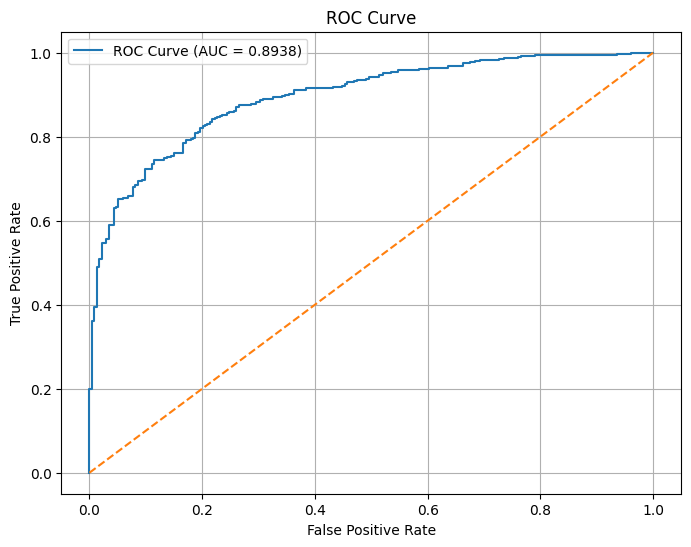

In [ ]:
# =========================================================
# ROC CURVE + AUC
# =========================================================

from sklearn.metrics import (

    roc_curve,

    auc
)

fpr, tpr, thresholds = roc_curve(

    true_labels,

    predictions
)

roc_auc = auc(

    fpr,

    tpr
)

print("========== ROC AUC ==========\n")

print(f"AUC : {roc_auc:.4f}")

plt.figure(figsize=(8,6))


# =========================================================
# COURBE ROC
# =========================================================

plt.plot(

    fpr,

    tpr,

    label = f"ROC Curve (AUC = {roc_auc:.4f})"
)


# =========================================================
# LIGNE ALEATOIRE
# =========================================================

# représente un modèle aléatoire

plt.plot(

    [0,1],

    [0,1],

    linestyle = "--"
)

plt.title("ROC Curve")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid()

plt.show()

In [ ]:
# =========================================================
# OPTIMISATION DU THRESHOLD
# =========================================================

import pandas as pd

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score
)


# =========================================================
# LISTE DES THRESHOLDS
# =========================================================

thresholds = np.arange(

    0.1,

    1.0,

    0.1
)

results = []


# =========================================================
# TEST DES THRESHOLDS
# =========================================================

for threshold in thresholds:


    # =====================================================
    # CONVERSION EN CLASSES
    # =====================================================

    predicted_classes = (

        predictions >= threshold

    ).astype(int)


    predicted_classes = predicted_classes.flatten()


    # =====================================================
    # METRIQUES
    # =====================================================

    accuracy = accuracy_score(

        true_labels,

        predicted_classes
    )


    precision = precision_score(

        true_labels,

        predicted_classes
    )


    recall = recall_score(

        true_labels,

        predicted_classes
    )


    f1 = f1_score(

        true_labels,

        predicted_classes
    )


    # =====================================================
    # STOCKAGE
    # =====================================================

    results.append([

        threshold,

        accuracy,

        precision,

        recall,

        f1
    ])


# =========================================================
# DATAFRAME
# =========================================================

results_df = pd.DataFrame(

    results,

    columns = [

        "Threshold",

        "Accuracy",

        "Precision",

        "Recall",

        "F1-score"
    ]
)

print("\n========== RESULTATS THRESHOLDS ==========\n")

print(results_df)


========== RESULTATS THRESHOLDS ==========

   Threshold  Accuracy  Precision    Recall  F1-score
0        0.1  0.625000   0.625000  1.000000  0.769231
1        0.2  0.641026   0.635621  0.997436  0.776447
2        0.3  0.727564   0.701465  0.982051  0.818376
3        0.4  0.772436   0.755144  0.941026  0.837900
4        0.5  0.802885   0.798658  0.915385  0.853047
5        0.6  0.820513   0.845771  0.871795  0.858586
6        0.7  0.809295   0.875346  0.810256  0.841545
7        0.8  0.791667   0.906250  0.743590  0.816901
8        0.9  0.741987   0.959839  0.612821  0.748044


In [ ]:
# =========================================================
# MEILLEUR THRESHOLD
# =========================================================

best_threshold = 0.7

print(f"Best Threshold : {best_threshold}")

Best Threshold : 0.7


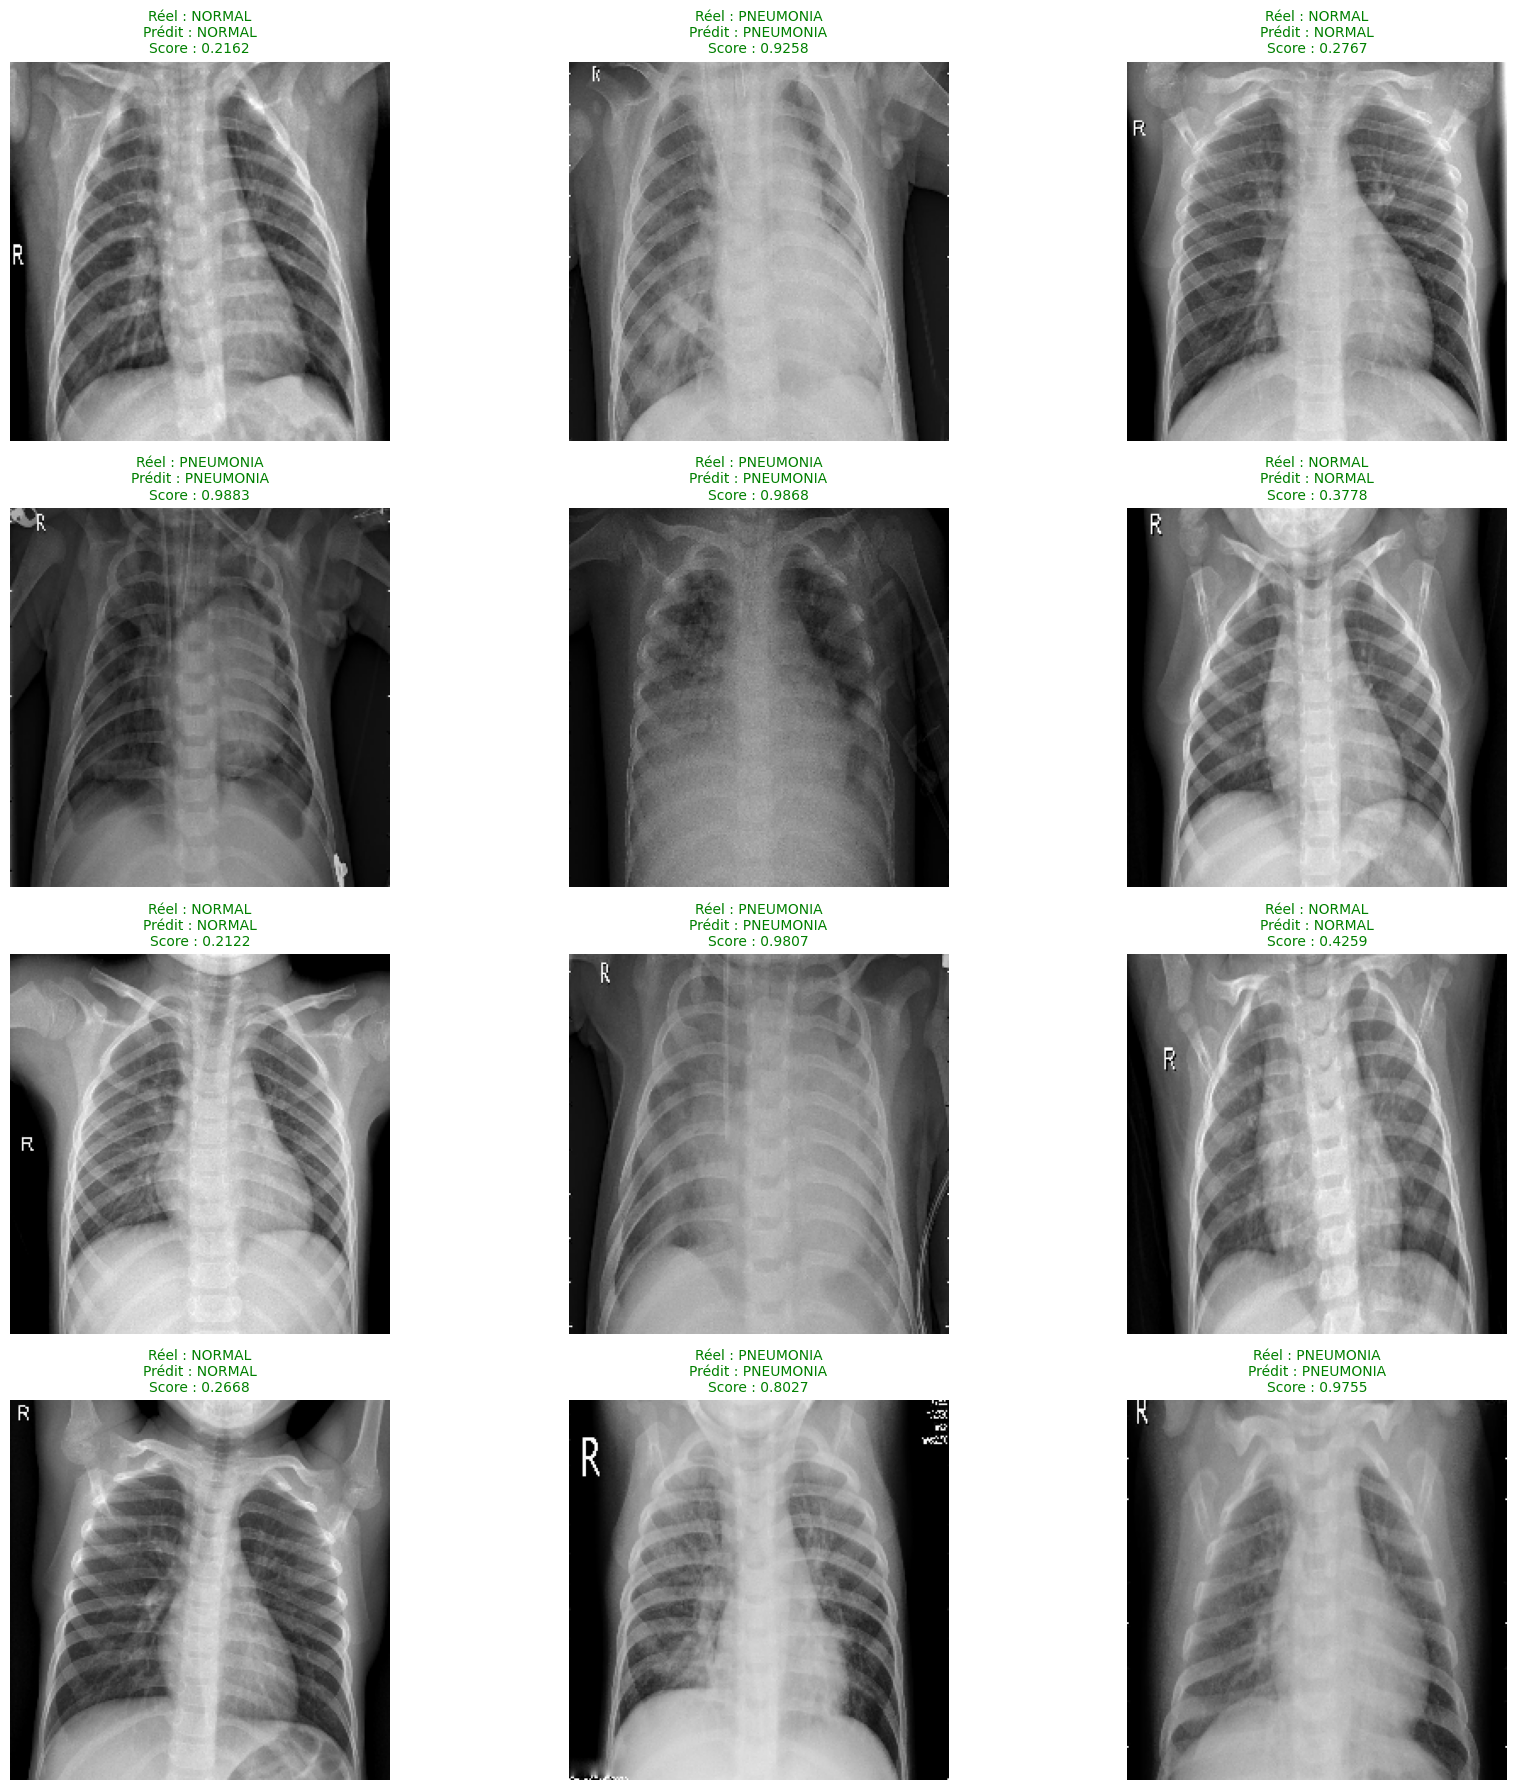

In [ ]:
# =========================================================
# TEST DU MODELE
# =========================================================

from tensorflow.keras.utils import load_img

from tensorflow.keras.utils import img_to_array


normal_dir = "/content/chest_xray/chest_xray/test/NORMAL"

pneumonia_dir = "/content/chest_xray/chest_xray/test/PNEUMONIA"

# =========================================================
# RECUPERATION DES IMAGES
# =========================================================

normal_images = [

    os.path.join(normal_dir, img)

    for img in os.listdir(normal_dir)
]


pneumonia_images = [

    os.path.join(pneumonia_dir, img)

    for img in os.listdir(pneumonia_dir)
]


# =========================================================
# SELECTION ALEATOIRE
# =========================================================

selected_normal = random.sample(

    normal_images,

    6
)


selected_pneumonia = random.sample(

    pneumonia_images,

    6
)


# =========================================================
# LISTE FINALE
# =========================================================

image_paths = (

    selected_normal +

    selected_pneumonia
)

random.shuffle(image_paths)

best_threshold = 0.7

plt.figure(figsize=(18,18))

for i, image_path in enumerate(image_paths):

    image = load_img(

        image_path,

        target_size = (224,224)
    )

    image_array = img_to_array(image)


    # =====================================================
    # NORMALISATION
    # =====================================================

    image_array = image_array / 255.0


    # =====================================================
    # AJOUT DIMENSION BATCH
    # =====================================================

    image_array = np.expand_dims(

        image_array,

        axis = 0
    )


    # =====================================================
    # PREDICTION
    # =====================================================

    prediction = model.predict(

        image_array,

        verbose = 0
    )


    # =====================================================
    # SCORE
    # =====================================================

    probability = prediction[0][0]


    # =====================================================
    # CLASSE PREDITE
    # =====================================================

    if probability > best_threshold:

        predicted_class = "PNEUMONIA"

    else:

        predicted_class = "NORMAL"


    # =====================================================
    # VRAIE CLASSE
    # =====================================================

    if "PNEUMONIA" in image_path:

        true_class = "PNEUMONIA"

    else:

        true_class = "NORMAL"

    if predicted_class == true_class:

        color = "green"

    else:

        color = "red"

    plt.subplot(4,3,i+1)

    plt.imshow(image)

    plt.axis("off")

    plt.title(

        f"Réel : {true_class}\n"
        f"Prédit : {predicted_class}\n"
        f"Score : {probability:.4f}",

        color = color,

        fontsize = 10
    )

plt.tight_layout()

plt.show()

In [ ]:
# =========================================================
# SAUVEGARDE DES INFORMATIONS DU MODELE
# =========================================================

import json


# =========================================================
# INFORMATIONS DU MODELE
# =========================================================

model_info = {

    # =====================================================
    # NOM DES CLASSES
    # =====================================================

    "class_names": [

        "NORMAL",

        "PNEUMONIA"
    ],


    # =====================================================
    # TAILLE DES IMAGES
    # =====================================================

    "image_size": [

        224,

        224
    ],


    # =====================================================
    # THRESHOLD OPTIMAL
    # =====================================================

    "best_threshold": 0.7
}


# =========================================================
# SAUVEGARDE JSON
# =========================================================

with open(

    "model_config.json",

    "w"
) as file:

    json.dump(

        model_info,

        file,

        indent = 4
    )

print("Configuration du modèle sauvegardée avec succès !")

Configuration du modèle sauvegardée avec succès !


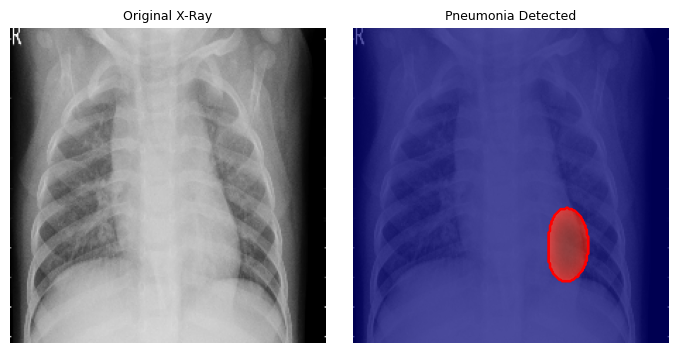

In [ ]:
# =========================================================
# AFFICHAGE DES 2 IMAGES
# =========================================================

plt.figure(figsize=(7,3.5))

# =========================================================
# IMAGE ORIGINALE
# =========================================================

plt.subplot(1,2,1)

plt.imshow(original_img)

plt.title(
    "Original X-Ray",
    fontsize=9
)

plt.axis("off")

# =========================================================
# IMAGE AVEC HEATMAP
# =========================================================

plt.subplot(1,2,2)

plt.imshow(original_img)

if predicted_class == "PNEUMONIA":

    plt.imshow(

        focused_heatmap,

        cmap="jet",

        alpha=0.65
    )

    plt.contour(

        focused_heatmap,

        levels=3,

        colors="red",

        linewidths=1
    )

    title_text = "Pneumonia Detected"

else:

    title_text = "No Pneumonia"

plt.title(
    title_text,
    fontsize=9
)

plt.axis("off")

plt.tight_layout(
    pad=1
)

plt.show()

In [ ]:
from google.colab import files

files.download("best_cnn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>